# ANÁLISIS EXPLORATORIO DE DATOS SOBRE LAS TENDENCIAS CINEMATOGRÁFICAS MUNDIALES (2010–2025)
## Desarrollo - Fases 1 Ecosistema

---

### **INFORMACIÓN GENERAL Y METADATOS ACADÉMICOS**
- **Asignatura:** Programación para la Ciencia de Datos
- **Profesor: Omar Salinas Silva** 
- **Fecha de Entrega:** Domingo 8 de Noviembre de 2026
- **Integrantes del Grupo 4:**
  1. Daniela Baeza Rocha
  2. Juan González Elgueta
  3. Elías Manríquez Armijo
  4. Yestxander Rada Gutierrez

---

## 1: COMPRENSIÓN DEL NEGOCIO (BUSINESS UNDERSTANDING)

### 1.1 Contexto de la Industria Cinematográfica Mundial (2010–2025)
Durante el período comprendido entre 2010 y 2025, la industria del cine ha experimentado transformaciones estructurales impulsadas por la digitalización, la masificación de las plataformas de streaming, las variaciones en las preferencias de los espectadores y los cambios macroeconómicos globales. Comprender los factores determinantes de la rentabilidad y popularidad de las producciones cinematográficas es fundamental para la toma de decisiones estratégicas en producción, distribución y marketing.

### 1.2 Formulación del Problema de Investigación
**Pregunta Central:** Análisis exploratorio de datos (AED) sobre las tendencias cinematográficas mundiales durante un período de 15 años (2010-2025).

### 1.3 Objetivos del Estudio
- **Objetivo General:** Desarrollar un Análisis Exploratorio de Datos  sobre un conjunto de datos de 17,978 películas de The Movie Database (TMDB) comprendidas entre 2010 y 2025.


## 2: COMPRENSIÓN DE LOS DATOS (DATA UNDERSTANDING)

### 2.1 Carga del Entorno y Librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch

# Configuración de estilo visual
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
print("Librerías cargadas exitosamente.")

Librerías cargadas exitosamente.


### 2.2 Carga Inicial del Dataset TMDB

In [2]:
np.random.seed(42)  # semilla para reproducibilidad

rutas_posibles = [
    Path("../data/raw/movies_raw.csv")
]

ruta = next((p for p in rutas_posibles if p.exists()), None)

if ruta is None:
    try:
        from google.colab import files
        cargados = files.upload()
        nombre_archivo = next(iter(cargados))
        ruta = Path(nombre_archivo)
    except Exception as e:
        raise FileNotFoundError(
            "No se encontró BaseFinal.csv. Súbelo al entorno de ejecución."
        ) from e

df = pd.read_csv(ruta)

print(f"Archivo cargado: {ruta}")
print(f"Filas: {df.shape[0]:,}")
print(f"Columnas: {df.shape[1]:,}")

Archivo cargado: ..\data\raw\movies_raw.csv
Filas: 17,978
Columnas: 16


#### 2.2.1 Inspección Inicial Dataset TMDB

In [3]:
print("Dimensiones del conjunto de datos:", df.shape)


Dimensiones del conjunto de datos: (17978, 16)


In [4]:
# Muestra Aleaoria de 5 filas del DataFrame
print("Muestra 5 filas aleatorias del dataset")
display(df.sample(5, random_state=42))

Muestra 5 filas aleatorias del dataset


,movie_id,title,release_date,status,budget,revenue,runtime,genres,production_companies,production_countries,spoken_languages,original_language,vote_average,vote_count,popularity,adult
5954,10317,Our Brand Is Crisis,2015-09-11,Released,28000000,7002261,107,Comedy|Drama,Participant|Smokehouse Pictures,United States of America,English,en,5.871,533,1.9643,False
2616,149893,Two Lives,2012-10-19,Released,0,1649260,97,Drama|Thriller,Helgeland Film|Zinnober Film- und Fernsehprodu...,Germany|Norway,Deutsch|Norsk,de,6.574,74,0.8469,False
4518,277594,Hercules Reborn,2014-07-08,Released,0,0,90,Adventure|Action,The Asylum,United States of America,English,en,4.216,74,0.4225,False
4400,343750,Dollface,2014-05-28,Released,0,0,95,Horror,Horse Creek Productions,United States of America,English,en,5.491,57,0.3668,False
11789,630027,Fragtime,2019-11-22,Released,0,0,61,Animation|Romance|Science Fiction|Comedy,Tear Studio|Pony Canyon|Akita Shoten|Sotsu|WOW...,Japan,日本語,ja,6.118,51,0.8834,False


In [5]:
print("Información general del DataFrame")
print(df.info())
   

Información general del DataFrame
<class 'pandas.DataFrame'>
RangeIndex: 17978 entries, 0 to 17977
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   movie_id              17978 non-null  int64  
 1   title                 17978 non-null  str    
 2   release_date          17978 non-null  str    
 3   status                17978 non-null  str    
 4   budget                17978 non-null  int64  
 5   revenue               17978 non-null  int64  
 6   runtime               17978 non-null  int64  
 7   genres                17968 non-null  str    
 8   production_companies  17484 non-null  str    
 9   production_countries  17802 non-null  str    
 10  spoken_languages      17886 non-null  str    
 11  original_language     17978 non-null  str    
 12  vote_average          17978 non-null  float64
 13  vote_count            17978 non-null  int64  
 14  popularity            17978 non-null  float64
 

#### 2.2.2 Tipos de variables (Diccionario de datos)

In [6]:
resumen_variables = pd.DataFrame({
    "tipo":df.dtypes.astype(str),
    "n_unicos": df.nunique(dropna=True),
    "faltantes": df.isna().sum(),
    "faltantes_%": (df.isna().mean() * 100).round(2),
    "iguales_a_0":(df==0).sum()
})
resumen_variables["ejemplos"] = [
    df[col].dropna().astype(str).unique()[:4].tolist()
    for col in df.columns
]
display(resumen_variables)

,tipo,n_unicos,faltantes,faltantes_%,iguales_a_0,ejemplos
movie_id,int64,17978,0,0.00,0,"[113727, 67250, 43615, 38883]"
title,str,17322,0,0.00,0,"[Dark Seduction, 12, Lula, the Son of Brazil, ..."
release_date,str,4582,0,0.00,0,"[2010-01-01, 2010-01-03, 2010-01-04, 2010-01-05]"
status,str,1,0,0.00,0,[Released]
budget,int64,1091,0,0.00,12463,"[0, 9500000, 20000000, 2000000]"
revenue,int64,6443,0,0.00,11156,"[0, 3785593, 3807808, 22039646]"
runtime,int64,217,0,0.00,46,"[89, 3, 130, 90]"
genres,str,2857,10,0.06,0,"[Drama|Thriller|Romance, Comedy, Drama|History..."
production_companies,str,15387,494,2.75,0,"[Lionsgate, LC Barreto|Filmes do Equador|Inter..."
production_countries,str,1808,176,0.98,0,"[Mexico, United States of America, Brazil, Fra..."


**Observación inicial del conjunto de datos**
Filas: 17.978
|Columna|Observación|Posible Acción|
|--|--|--|
|**movie_id**|Identificador único de cada película|Al ser 17978 no existen filas repetidas de este valor, por lo que se debería excluir|
|**title**|17.322 valores únicos por lo que existen títulos repetidos (no necesariamente es por que sea la misma película)||
|**release_date**|Existen 4582 fechas de estreno|Revisar si las fechas tienen formato correcto e inicio y fin|
|**status**|Único valor, por lo que no aporta variabilidad al análisis|Excluir del análisis|
|**budget**|Presenta 12.463 valores igual a 0 (69,32% de los casos)|Evaluar su utilidad en el análisis|
|**revenue**|Presenta 11.156 registros iguales a 0 (62,05% de los casos)|Evaluar su utilidad en el análisis|
|**runtime**|Tiene 217 valores únicos y 46 valores iguales a 0 indica los minutos puede ser que sea cortos de segundos|Evaluar escalamiento si el análisis lo requiere|
|**genres**|Existen 10 filas sin generos y una película puede tener múltiples generos por película separado por "\|"|Separar valores para el análisis según su relevancia|
|**production_companies**|Tiene 494 filas faltantes, presenta múltiples productoras por películas también separado por "\|"|Separar valores para el análisis según su relevancia|
|**spoken_languages**|A 92 filas les falta este campo, las película pueden tener múltiples idiomas hablados en pantalla en la celda se encuentran separados por "\|"|Separar valores para el análisis según su relevancia|
|**original_language**|Tiene 80 valores únicos|Revisar distribución para ver idioma predominantes| 
|**vote_average**|Muestra la valoración promedio de las películas|Analizar Estadísticas descriptiva| 
|**vote_count**|Muestra la cantidad de votos recibidos|Analizar Estadísticas descriptiva| 
|**popularity**|Muestra la popularidad de cada película|Analizar Estadísticas descriptiva| 
|**adult**|Único valor, por lo que no aporta variabilidad al análisis|Excluir del análisis|

#### 2.2.3 Estadisticas Dataset TMDB

In [8]:
print("\nEstadísticas descriptivas")
display(df.describe(include="all").round(2))


Estadísticas descriptivas


,movie_id,title,release_date,status,budget,revenue,runtime,genres,production_companies,production_countries,spoken_languages,original_language,vote_average,vote_count,popularity,adult
count,17978.00,17978,17978,17978,1.797800e+04,1.797800e+04,17978.00,17968,17484,17802,17886,17978,17978.00,17978.00,17978.00,17978
unique,NaN,17322,4582,1,NaN,NaN,NaN,2857,15387,1808,1505,80,NaN,NaN,NaN,1
top,NaN,Return,2020-10-02,Released,NaN,NaN,NaN,Drama,The Asylum,United States of America,English,en,NaN,NaN,NaN,False
freq,NaN,9,21,17978,NaN,NaN,NaN,1473,68,6076,8270,10615,NaN,NaN,NaN,17978
mean,499968.87,NaN,NaN,NaN,8.389049e+06,2.359657e+07,99.50,NaN,NaN,NaN,NaN,NaN,6.33,740.98,2.07,NaN
std,334180.24,NaN,NaN,NaN,2.863707e+07,1.096575e+08,25.05,NaN,NaN,NaN,NaN,NaN,0.88,2122.98,3.08,NaN
min,189.00,NaN,NaN,NaN,0.000000e+00,0.000000e+00,0.00,NaN,NaN,NaN,NaN,NaN,1.83,50.00,0.01,NaN
25%,253307.75,NaN,NaN,NaN,0.000000e+00,0.000000e+00,90.00,NaN,NaN,NaN,NaN,NaN,5.79,80.00,0.79,NaN
50%,444171.00,NaN,NaN,NaN,0.000000e+00,0.000000e+00,98.00,NaN,NaN,NaN,NaN,NaN,6.38,152.00,1.28,NaN
75%,685586.75,NaN,NaN,NaN,2.300000e+06,1.869959e+06,110.00,NaN,NaN,NaN,NaN,NaN,6.95,427.75,2.16,NaN


**Observaciones**

**runtime**: La media es de 99,5 segundos mientras que la mediana es de 98 segundos por lo que la duración se concentra dentro de estos rangos. La duración máxima de una película es de 585 minutos y el mínimo es de 0 segundos por lo que se deben revisar para ver el trato que se les da a estas celdas.

**budget y revenue**: La media en ambas son superiores a sus medianas esto se debe a que el 60% aprox. de sus valores son 0. Por lo que no podría representar adecuadamente la información del comportamiento de las películas a nivel económico usando el set completo de datos.    

**vote_average**: La media de 6,33 y la mediana de 6,38 son similares. Lo que sugiere que las valoraciones están equilibradas en esos rangos. El 50% de las notas se encuentra concentrado entre los 5,79 y 6,95

**vote_count**: Presenta una gran diferencia entre la media = 740,98 y la mediana de 152,0 (4,9 veces mayor) lo que indica una alta asimetría hacia valores altos. La cantidad de votos máximos para una película fue de 40365. Se observa el mínimo de votos comienza en 50 posible sesgo de selección.

**popularity**:  La media es de 2,07 superando a la mediana de 1,28 y con un valor máximo de 103,86 (el 75% está por debajo de los 2,16 puntos) lo que sugiere una distribución asimétrica con películas con valores de popularidad muy superiores al resto.


In [9]:
fechas_validas = pd.to_datetime(
    df['release_date'],
    errors='coerce'
)
print("\nFechas inválidas:", fechas_validas.isna().sum())
print("Fecha mínima:", fechas_validas.min())
print("Fecha máxima:", fechas_validas.max())


Fechas inválidas: 0
Fecha mínima: 2010-01-01 00:00:00
Fecha máxima: 2025-12-30 00:00:00


El dataset tiene una Fecha Inicial del 01-01-2010 y fecha final 30-12-2025 , no viene con fechas inválidas. Por lo que no es necesario transformar.

### 2.3 Visualizaciones del Dataset TMDB

**Histograma de datos**

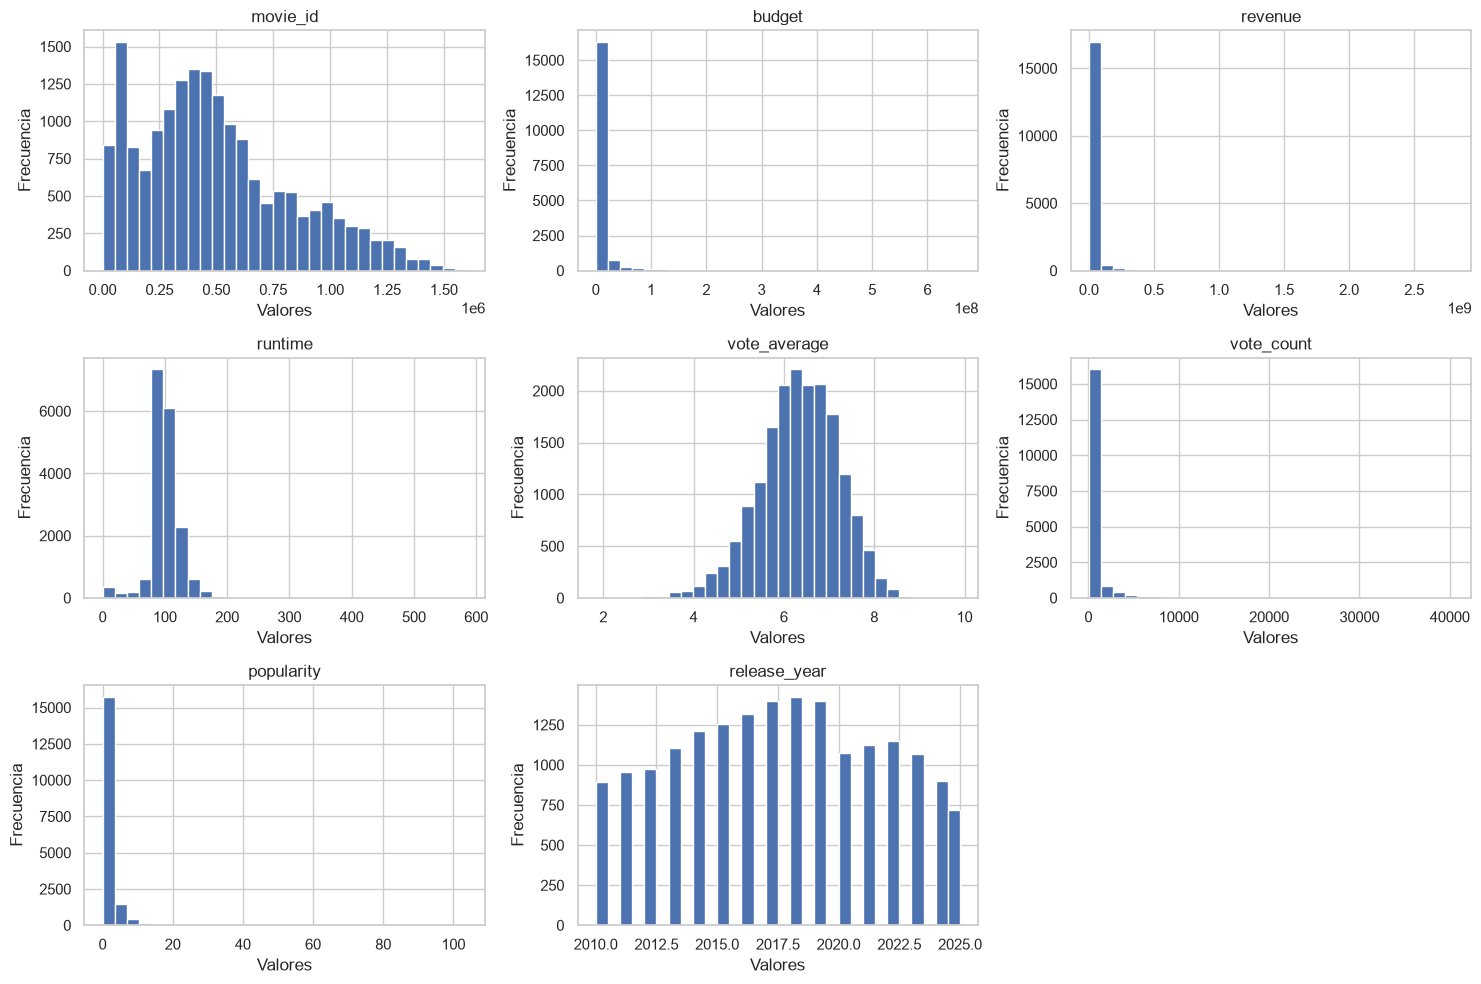

In [27]:
# Escoger solo columnas sin valores nulos
columnas_completas = df.columns[df.isnull().sum() == 0]

df_numerico = df[columnas_completas].select_dtypes(include='number')

axes = df_numerico.hist(figsize=(15, 10), bins=30)

for ax in axes.flatten():
    ax.set_xlabel('Valores')
    ax.set_ylabel('Frecuencia')
# Definir eje x e y para cada gráfico
plt.tight_layout()
plt.show()
# Histograma que indica la distribución de frecuencia de películas para cada variable numérica del dataset.

In [6]:
# Crear la variable release_year a partir de release_date.
df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")
df["release_year"] = df["release_date"].dt.year

# Filtrar período de análisis
df = df[(df["release_year"] >= 2010) & (df["release_year"] <= 2025)]

**Evolución de películas estrenadas por año**

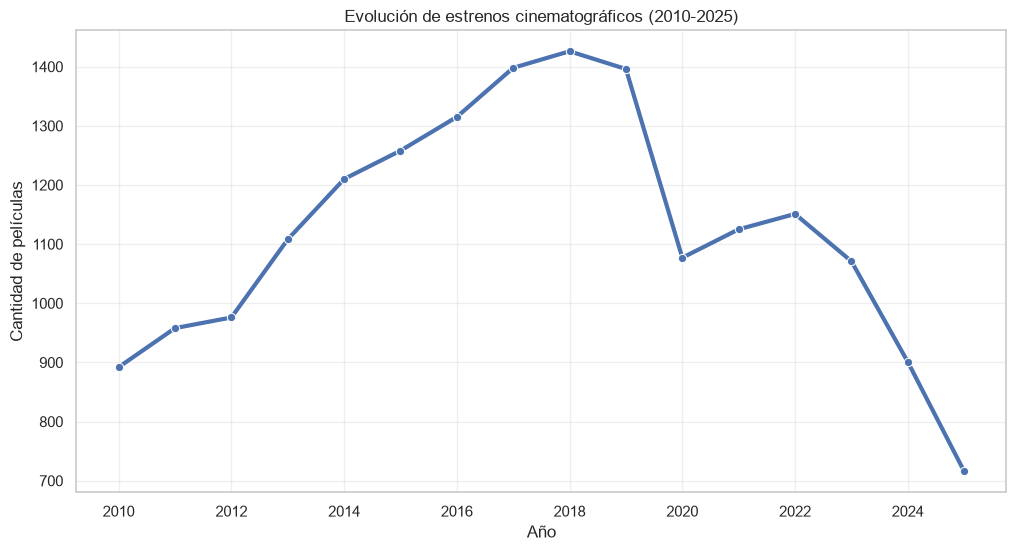

In [7]:
movies_year = (
    df.groupby("release_year")
      .size()
      .reset_index(name="movies")
)

plt.figure(figsize=(12,6))

sns.lineplot(
    data=movies_year,
    x="release_year",
    y="movies",
    marker="o",
    linewidth=3
)

plt.title("Evolución de estrenos cinematográficos (2010-2025)")
plt.xlabel("Año")
plt.ylabel("Cantidad de películas")
plt.grid(alpha=0.3)

plt.show()

Aqui interpretación salida

**Evolución de la popularidad promedio**

Permite evaluar cómo cambió el interés del público durante el periodo.

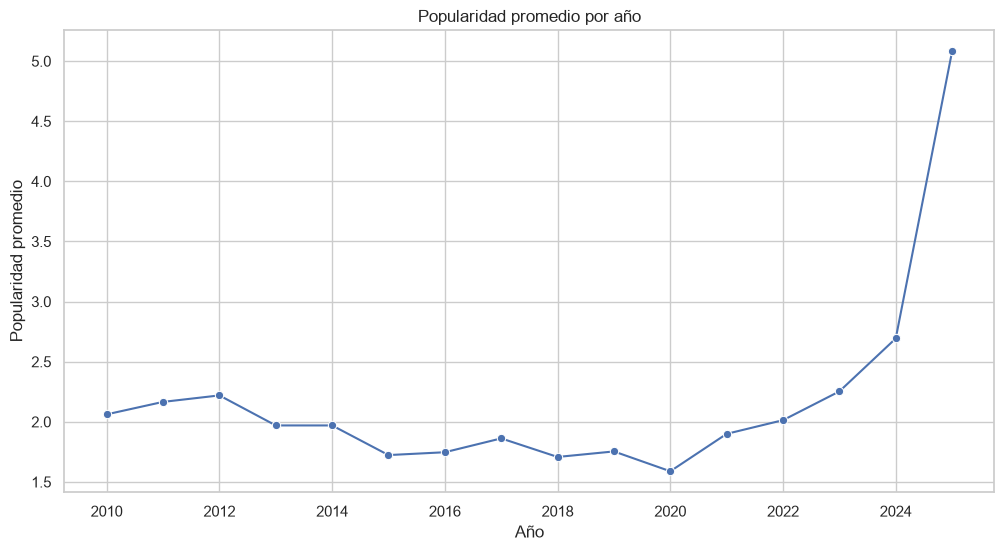

In [8]:
popularidad = (
    df.groupby("release_year")["popularity"]
      .mean()
      .reset_index()
)

plt.figure(figsize=(12,6))

sns.lineplot(
    data=popularidad,
    x="release_year",
    y="popularity",
    marker="o"
)

plt.title("Popularidad promedio por año")
plt.xlabel("Año")
plt.ylabel("Popularidad promedio")

plt.show()

Interpretacion aqui - Puede mostrar períodos donde la industria logró mayor atención global.

**Presupuesto vs Recaudación**

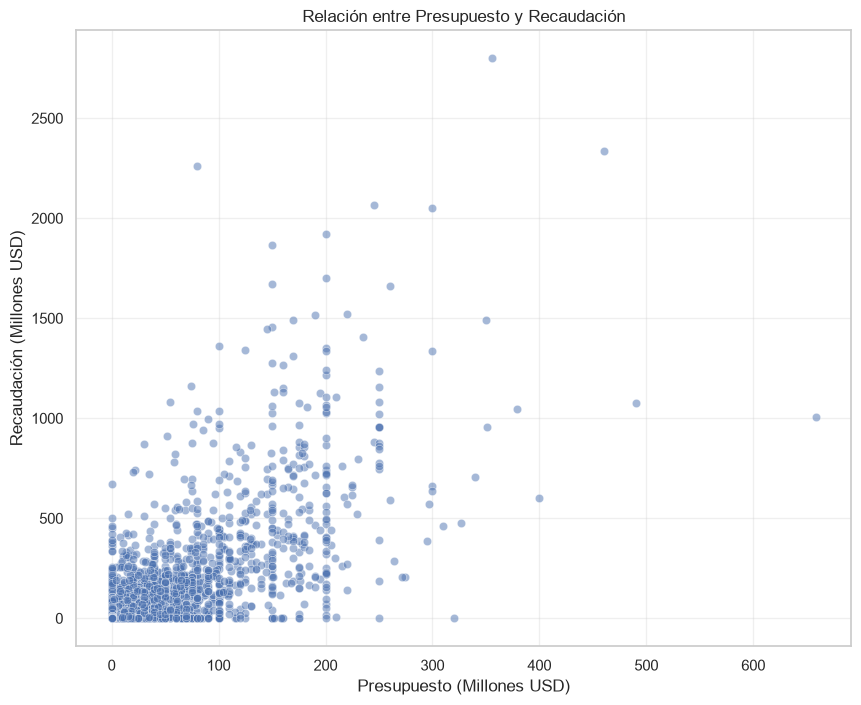

In [9]:
plt.figure(figsize=(10, 8))

sns.scatterplot(
    data=df,
    x="budget",
    y="revenue",
    alpha=0.5
)

# Formato en millones
formatter = FuncFormatter(lambda x, pos: f'{x/1_000_000:.0f}')

plt.gca().xaxis.set_major_formatter(formatter)
plt.gca().yaxis.set_major_formatter(formatter)

plt.title("Relación entre Presupuesto y Recaudación")
plt.xlabel("Presupuesto (Millones USD)")
plt.ylabel("Recaudación (Millones USD)")

plt.grid(alpha=0.3)

plt.show()

Interpretacion aqui

**Top países productores**

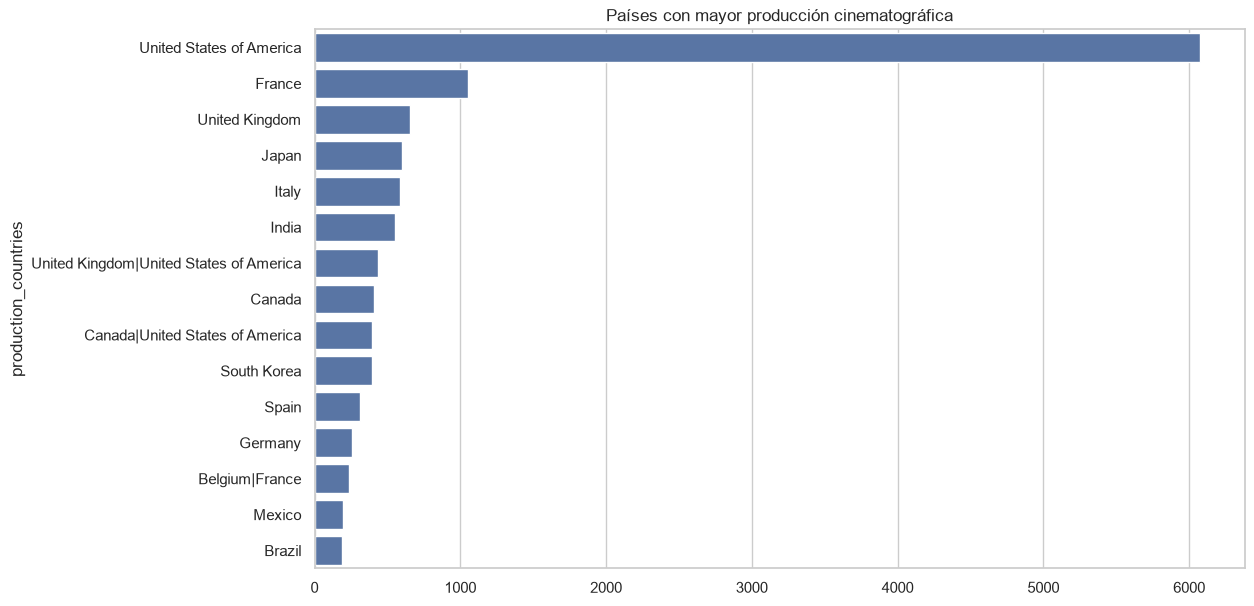

In [10]:
countries = (
    df["production_countries"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
)

top_countries = countries.value_counts().head(15)

plt.figure(figsize=(12,7))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title("Países con mayor producción cinematográfica")

plt.show()

**Evolucion de la duración de películas en el tiempo**

In [33]:
# Eliminar datos faltantes
df_runtime = df_runtime.dropna()

# Eliminar duraciones no válidas
df_runtime = df_runtime[df_runtime['runtime'] > 0]

In [38]:
df_runtime['runtime_hours'] = df_runtime['runtime'] / 60
# Convertir minutos a horas ya que el dataframe entrega en minutos

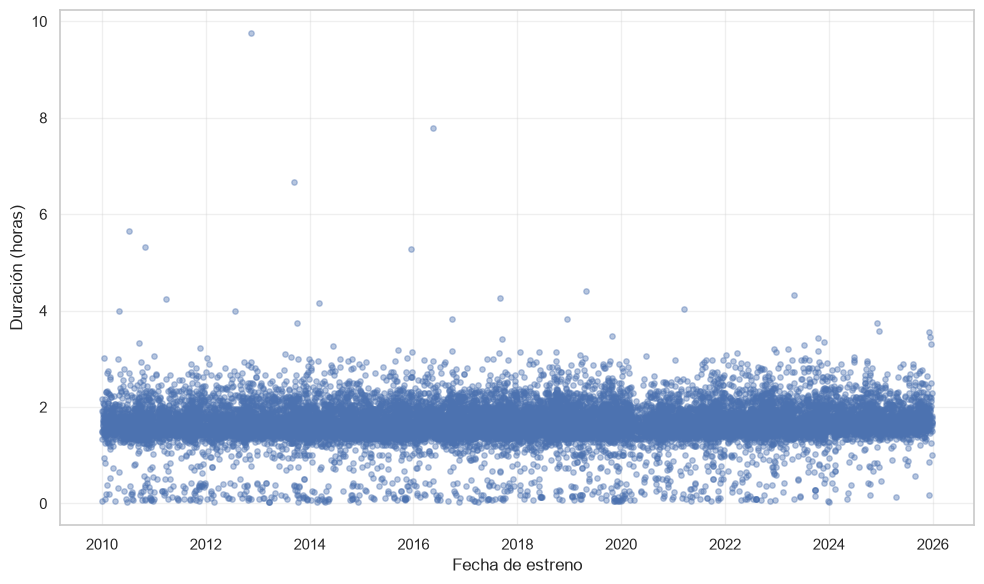

In [39]:
plt.scatter(
    df_runtime['release_date'],
    df_runtime['runtime_hours'],
    alpha=0.4,
    s=15
)

plt.xlabel('Fecha de estreno')
plt.ylabel('Duración (horas)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Evolucion de la popularidad con respecto a la duración de las películas**

In [48]:
# Eliminar datos faltantes
df_popularity = df[['popularity', 'runtime']].copy()
df_popularity = df_popularity.dropna()

# Eliminar duraciones y popularidades no válidas
df_popularity = df_popularity[df_popularity['popularity'] > 0]
df_popularity = df_popularity[df_popularity['runtime'] > 0]

In [51]:
df_popularity['runtime_hours'] = df_popularity['runtime'] / 60

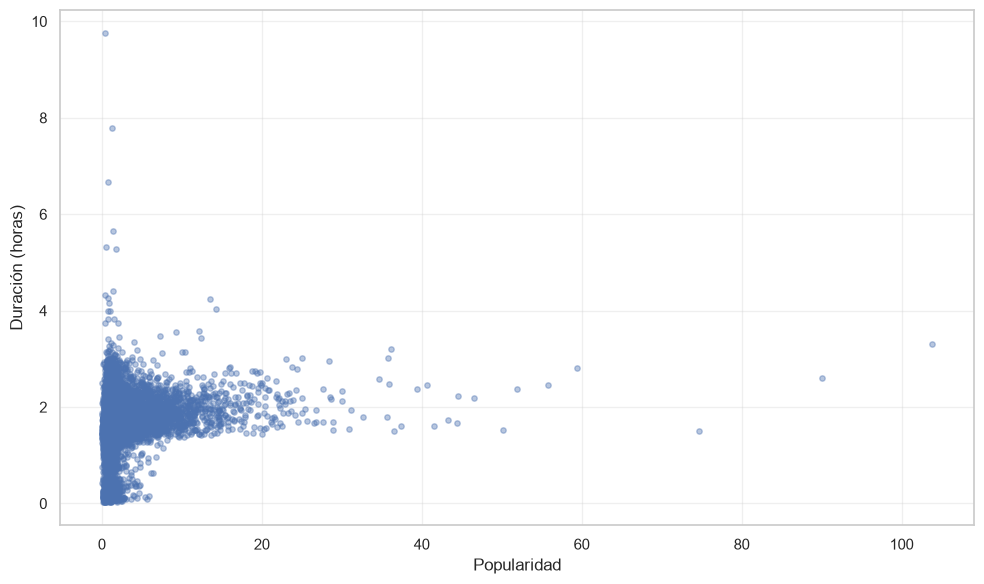

In [55]:
plt.scatter(
    df_popularity['popularity'],
    df_popularity['runtime_hours'],
    alpha=0.4,
    s=15
)

plt.xlabel('Popularidad')
plt.ylabel('Duración (horas)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()